# Can a Model Spot a Space Mouse?

Follow-up to `02_clock_replication.ipynb`. That notebook found the clock shift only in mice dissected on the ISS. Here the question becomes a machine learning one: **if a model only sees a mouse's liver gene readings, can it tell whether that mouse went to space, even on a mission it has never seen?**

**Prediction from notebook 02:** it should work on the missions dissected on the ISS (RR-1, RR-6) and struggle on the ones flown home first (RR-9, RR-23).

### Four ideas you need
- **Logistic regression:** a simple model that gives each gene a weight and adds them up into a "probability this mouse went to space". Simple on purpose, because we only have 69 mice.
- **Leave one mission out:** train on four missions, test on the fifth. This is the honest test, because the model never sees any mouse from the test mission.
- **AUC:** if you pick one space mouse and one Earth mouse from the test mission, AUC is how often the model ranks the space mouse higher. 0.5 is a coin flip, 1.0 is perfect, and below 0.5 means it has them backwards.
- **Shuffle baseline:** with only 4–10 test mice, a high AUC can happen by pure luck. So we shuffle the labels, retrain 200 times, and see how high luck alone gets. A result only counts if it beats that.

Run the cells in order. Cell 4 takes about 8 minutes.

# Cell 1  //  Setup

Same setup as before, plus scikit-learn for the model (already installed in Colab).

In [1]:
import requests, io, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

INK, PINK, MAUVE, BLUSH = "#3A1C2B", "#E8447A", "#8C6B76", "#FCE4EC"

def find_files(obj):
    out = []
    if isinstance(obj, dict):
        if "file_name" in obj:
            out.append(obj)
        for v in obj.values():
            out += find_files(v)
    elif isinstance(obj, list):
        for v in obj:
            out += find_files(v)
    return out

# Cell 2  //  One Row per Mouse

The NASA files contain every mouse's own gene readings next to the summary stats. This builds a table with one row per mouse and one column per gene, labeled 1 for space and 0 for Earth, using the same groups as notebook 02. The readings are put on a log scale, and only genes measured on all five missions and not near zero are kept.

In [2]:
MISSIONS = {"48": "RR-1", "245": "RR-6", "137": "RR-3", "242": "RR-9", "463": "RR-23"}

def groups(col):
    return col.split("_", 1)[1][1:-1].split(")v(")

def r_name(group):
    # the sample table writes "Space Flight & Carcass" as "Space.Flight...Carcass"
    return re.sub(r"[^A-Za-z0-9]", ".", group)

def download(osd, pick):
    files = find_files(requests.get(f"https://osdr.nasa.gov/osdr/data/osd/files/{osd}").json())
    f = sorted([f for f in files if pick(f["file_name"])], key=lambda f: "rrnarm" not in f["file_name"].lower())[0]
    return pd.read_csv(io.StringIO(requests.get("https://osdr.nasa.gov" + f["remote_url"]).text))

def load_mice(osd):
    df = download(osd, lambda n: "differential_expression" in n.lower() and n.endswith(".csv"))
    samples = download(osd, lambda n: n.endswith("rna_seq_SampleTable_GLbulkRNAseq.csv"))
    samples.columns = ["sample", "condition"]

    # same Space Flight vs Ground Control groups as notebook 02
    pairs = [c for c in df.columns if c.startswith("Log2fc")
             and {g.split(" & ")[0] for g in groups(c)} == {"Space Flight", "Ground Control"}]
    fc_col = max(pairs, key=lambda c: all("Carcass" in g for g in groups(c)))
    label = {}
    for g in groups(fc_col):
        for s in samples.loc[samples["condition"] == r_name(g), "sample"]:
            label[s] = int(g.startswith("Space"))

    counts = df.dropna(subset=["SYMBOL"]).drop_duplicates("SYMBOL").set_index("SYMBOL")[list(label)]
    mice = np.log2(counts.T + 1)          # one row per mouse, one column per gene
    mice.index = [f"{MISSIONS[osd]} {s}" for s in mice.index]
    return mice, pd.Series(list(label.values()), index=mice.index)

X_parts, y_parts, mission_parts = [], [], []
for osd, name in MISSIONS.items():
    mice, labels = load_mice(osd)
    X_parts.append(mice); y_parts.append(labels); mission_parts.append(pd.Series(name, index=mice.index))
    print(f"{name:<6} {int(labels.sum())} space mice, {int((1 - labels).sum())} earth mice")

# keep genes measured on every mission and not near zero anywhere
shared = set.intersection(*[set(m.columns) for m in X_parts])
X = pd.concat([m[sorted(shared)] for m in X_parts])
mission = pd.concat(mission_parts)
y = pd.concat(y_parts)
X = X.loc[:, X.groupby(mission).mean().min() > np.log2(10 + 1)]
print(f"\n{len(X)} mice x {X.shape[1]} genes")

RR-1   5 space mice, 5 earth mice


RR-6   10 space mice, 10 earth mice


RR-3   6 space mice, 6 earth mice


RR-9   5 space mice, 4 earth mice


RR-23  9 space mice, 9 earth mice

69 mice x 12514 genes


# Cell 3  //  Train and Test

**Removing the mission effect:** each mission used different mice and was sequenced separately, so a model could learn "which mission is this" instead of "did this mouse go to space". Subtracting each mission's own average for every gene removes that. It uses only which mission a mouse came from, never its label.

Two models: one that only sees the 10 clock genes, and one that sees all genes. And two experiments:
1. **Leave one mission out:** train on four, test on the fifth.
2. **Train on RR-1 + RR-6:** train only on the missions where the clock shift showed up, test on the other three.

In [3]:
# every mission was sequenced separately, so subtract each mission's own average for every gene.
# this uses no labels, only which mission each mouse came from.
Xc = X - X.groupby(mission).transform("mean")

CLOCK = ["Npas2", "Bmal1", "Clock", "Cry1", "Per1", "Per3", "Nr1d1", "Nr1d2", "Tef", "Dbp"]
FEATURES = {"clock genes": [g for g in CLOCK if g in Xc.columns], "all genes": list(Xc.columns)}
print({k: len(v) for k, v in FEATURES.items()})

def model():
    # strong regularization (small C) because there are far more genes than mice
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, solver="liblinear", dual=True, max_iter=5000))

def auc_on(cols, train, test, labels=y):
    """Train on the `train` missions, return AUC on the `test` mission (always scored against the real labels)."""
    tr, te = mission.isin(train), mission == test
    prob = model().fit(Xc.loc[tr, cols], labels[tr]).predict_proba(Xc.loc[te, cols])[:, 1]
    return roc_auc_score(y[te], prob)

EXPERIMENTS = {
    "leave one mission out": [([m for m in MISSIONS.values() if m != t], t) for t in MISSIONS.values()],
    "train on RR-1 + RR-6": [(["RR-1", "RR-6"], t) for t in ["RR-3", "RR-9", "RR-23"]],
}

def run_all(labels=y):
    return {(exp, feat, test): auc_on(cols, train, test, labels)
            for exp, splits in EXPERIMENTS.items()
            for feat, cols in FEATURES.items()
            for train, test in splits}

real = run_all()
for (exp, feat, test), auc in real.items():
    print(f"{exp:<22} {feat:<12} test on {test:<6} AUC {auc:.2f}")

{'clock genes': 10, 'all genes': 12514}


leave one mission out  clock genes  test on RR-1   AUC 0.36
leave one mission out  clock genes  test on RR-6   AUC 1.00
leave one mission out  clock genes  test on RR-3   AUC 0.42
leave one mission out  clock genes  test on RR-9   AUC 0.20
leave one mission out  clock genes  test on RR-23  AUC 0.75
leave one mission out  all genes    test on RR-1   AUC 0.84
leave one mission out  all genes    test on RR-6   AUC 0.94
leave one mission out  all genes    test on RR-3   AUC 0.47
leave one mission out  all genes    test on RR-9   AUC 0.75
leave one mission out  all genes    test on RR-23  AUC 0.74
train on RR-1 + RR-6   clock genes  test on RR-3   AUC 0.31
train on RR-1 + RR-6   clock genes  test on RR-9   AUC 0.05
train on RR-1 + RR-6   clock genes  test on RR-23  AUC 0.67
train on RR-1 + RR-6   all genes    test on RR-3   AUC 0.56
train on RR-1 + RR-6   all genes    test on RR-9   AUC 0.55
train on RR-1 + RR-6   all genes    test on RR-23  AUC 0.59


# Cell 4  //  Is It Better Than Luck?

Shuffles the space/Earth labels inside each mission, retrains every model, and repeats 200 times. `luck 95%` is the AUC luck reaches 5% of the time. `p` is the share of shuffles that did at least as well as the real model. A result beats luck when p is under 0.05.

In [4]:
# with 4-10 mice per test mission, a high AUC can happen by luck.
# shuffle the space/earth labels inside each mission, retrain everything, and see how often luck does as well.
rng = np.random.default_rng(0)
N_SHUFFLES = 200
null = []
for i in range(N_SHUFFLES):
    shuffled = y.groupby(mission).transform(lambda s: pd.Series(rng.permutation(s.values), index=s.index))
    null.append(run_all(shuffled))
    if (i + 1) % 50 == 0:
        print(f"{i + 1}/{N_SHUFFLES} shuffles done")

results = pd.DataFrame([{"experiment": exp, "features": feat, "test": test, "AUC": auc,
                         "luck 95%": np.percentile([n[(exp, feat, test)] for n in null], 95),
                         "p": (sum(n[(exp, feat, test)] >= auc for n in null) + 1) / (N_SHUFFLES + 1)}
                        for (exp, feat, test), auc in real.items()])
results["beats luck"] = np.where(results["p"] < 0.05, "yes", "no")
print(results.round(2).to_string(index=False))

50/200 shuffles done


100/200 shuffles done


150/200 shuffles done


200/200 shuffles done
           experiment    features  test  AUC  luck 95%    p beats luck
leave one mission out clock genes  RR-1 0.36      1.00 0.55         no
leave one mission out clock genes  RR-6 1.00      1.00 0.10         no
leave one mission out clock genes  RR-3 0.42      0.67 0.76         no
leave one mission out clock genes  RR-9 0.20      0.90 0.81         no
leave one mission out clock genes RR-23 0.75      0.91 0.25         no
leave one mission out   all genes  RR-1 0.84      0.92 0.11         no
leave one mission out   all genes  RR-6 0.94      0.81 0.00        yes
leave one mission out   all genes  RR-3 0.47      0.67 0.67         no
leave one mission out   all genes  RR-9 0.75      1.00 0.26         no
leave one mission out   all genes RR-23 0.74      0.99 0.27         no
 train on RR-1 + RR-6 clock genes  RR-3 0.31      0.67 0.98         no
 train on RR-1 + RR-6 clock genes  RR-9 0.05      0.90 1.00         no
 train on RR-1 + RR-6 clock genes RR-23 0.67      0.89 

# Cell 5  //  The Results Chart

Each bar is one test. The black tick is how high luck gets 5% of the time. A bar only means something when it clears its tick. Saves `ml_results.png` at 9:16.

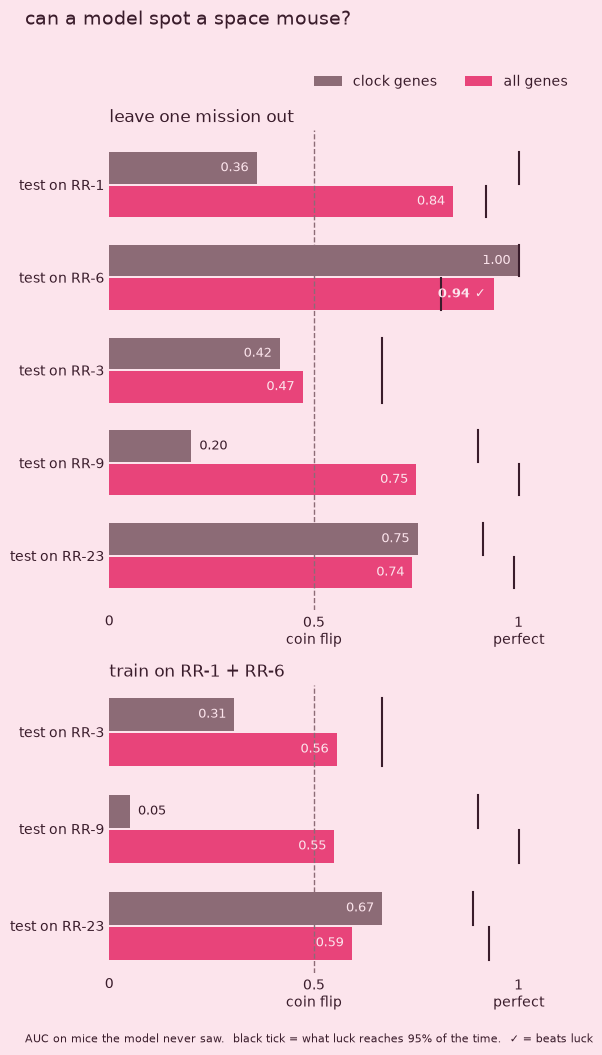

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(6, 10.7), facecolor=BLUSH,
                         gridspec_kw={"height_ratios": [5, 3]})
for ax, exp in zip(axes, EXPERIMENTS):
    r = results[results["experiment"] == exp]
    tests = list(dict.fromkeys(r["test"]))
    ax.set_facecolor(BLUSH)
    for k, (feat, color) in enumerate([("clock genes", MAUVE), ("all genes", PINK)]):
        rf = r[r["features"] == feat].set_index("test").loc[tests]
        ys = np.arange(len(tests)) + (k - 0.5) * 0.36
        ax.barh(ys, rf["AUC"], height=0.34, color=color, label=feat)
        for yy, (auc, luck, p) in zip(ys, rf[["AUC", "luck 95%", "p"]].values):
            ax.plot([luck, luck], [yy - 0.17, yy + 0.17], color=INK, lw=1.5)
            inside = auc > 0.2
            ax.text(auc - 0.02 if inside else auc + 0.02, yy, f"{auc:.2f}" + (" ✓" if p < 0.05 else ""),
                    va="center", ha="right" if inside else "left", color=BLUSH if inside else INK, fontsize=9,
                    fontweight="bold" if p < 0.05 else "normal")
    ax.axvline(0.5, color=MAUVE, lw=1, ls="--")
    ax.set_yticks(range(len(tests)), [f"test on {t}" for t in tests], color=INK)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.15)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5\ncoin flip", "1\nperfect"], color=INK)
    ax.set_title(exp, color=INK, fontsize=12, loc="left")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].legend(frameon=False, labelcolor=INK, loc="lower right", bbox_to_anchor=(1, 1.06), ncol=2)
fig.suptitle("can a model spot a space mouse?", color=INK, fontsize=14, x=0.05, ha="left")
fig.text(0.05, 0.015, "AUC on mice the model never saw.  black tick = what luck reaches 95% of the time.  ✓ = beats luck",
         color=INK, fontsize=8)
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
plt.savefig("ml_results.png", dpi=200, facecolor=BLUSH)
plt.show()

## What the Model Found

- **Only one result clearly beats luck:** the all-genes model tested on RR-6 (AUC 0.94, p < 0.01). RR-6 is the largest test set, with 20 mice.
- **Small test sets make luck look good.** With 9–10 test mice, models trained on shuffled labels reach AUC 0.9–1.0 about 5% of the time. So RR-9's 0.75 means nothing, and RR-1's 0.84 is close but not convincing (p = 0.11).
- **The clock genes point in opposite directions on different missions.** The clock-gene model trained on RR-1 + RR-6 scores 0.05 on RR-9, so it gets those mice almost perfectly backwards. That matches the reversed clock pattern in notebook 02. It's only 9 mice, so it's a clue, not proof.
- **The prediction is only partly supported.** The model generalizes to RR-6, a mission dissected on the ISS. It doesn't reliably transfer anywhere else, and with this few mice we can't separate "doesn't work" from "not enough data to tell".

**The honest conclusion:** 69 mice across five different missions is not enough to build a space-mouse detector that works on new missions. The most useful thing this notebook shows is *why* you always test against a shuffled baseline. Without it, AUC 0.75 on RR-9 and RR-23 would look like success.

**Limits:** different strains, sexes, ages and mission lengths; RR-9's ground controls were run a year later; the regularization strength (C = 0.1) was picked once and not tuned.

Data: NASA Space Biology Open Science Data Repository (OSDR), studies OSD-48, OSD-245, OSD-137, OSD-242 and OSD-463, accessed 2026-10-26 from https://registry.opendata.aws/nasa-osdr.